# LASSI - Power Efficiency

**OLLAMA API** + **Argo Gateway API** Jupyter Notebook version

+ ***Post LASSI-Judge version with pass@k***
+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


In [2]:
!nvidia-smi

Sat Sep  6 21:23:31 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.05              Driver Version: 560.35.05      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A30                     Off |   00000000:99:00.0 Off |                    0 |
| N/A   34C    P0             30W /  165W |       1MiB /  24576MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
!nvcc --version 

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Tue_Oct_29_23:50:19_PDT_2024
Cuda compilation tools, release 12.6, V12.6.85
Build cuda_12.6.r12.6/compiler.35059454_0


## Setup

In [4]:
import os
import json
import csv
import time
from datetime import datetime
from zoneinfo import ZoneInfo

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v3
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline_v3
%aimport lassi.get_power
%aimport lassi.argostream_curl
%aimport lassi.code_manager

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [5]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]

    Miniapps:
    -- miniMDock ["-lfile", "./input/7cpa/7cpa_ligand.pdbqt", "-nrun 100"]
    
    """

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # Enter source application to process through LASSI
    source_collection = "HeCBench"  # "Miniapps" "HeCBench"
    source_app = "segment-reduce"  # "miniMDock" jacobi
    make_script = False  # Used only for Miniapps
    
    build_script = False  # False (for HeCBench) Use for Altis only
    

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    3. miniMDock/bin/
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    lines_of_code = source_apps[source_collection][source_app]["code_lines"]
    if make_script:
        app_name = app_folder_name
        file_name = "kernels"
    else:
        app_name = "mt_" + app_folder_name + "-cuda_main"
        file_name = ""

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    verifyprompt = False  # True or False -- Print out LLM prompt in stdout to preview
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context_summaries_only = True  # True or False
    few_shot_learning = False  # True or False
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2, v3
    use_self_prompting = False  # True or False -- NOT USED IN v2, v3
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2, v3
    

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        elif make_script:
            code_compiler = "make"
            code_compiler_kwds = "API=CUDA DEVICE=GPU CARD=NVIDIA NUMWI=64"
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
            # -arch=sm_89 for RTX 5000
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # For A100 on Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        # !! TODO - REVIEW: code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc80"  # "-fopenmp -O3 -c"
        # For RTX 5000 Ada on Linux x86_64:
        # code_compiler = "/opt/nvidia/hpc_sdk/Linux_x86_64/25.7/compilers/bin/nvc++" # "g++"
        # code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc89"  # "-fopenmp -O3"
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1
        # ****************************
        # ---> EXPERIMENT UPDATE FIELD - Now, automated:
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto4mini"  # (max token = 128000)
    model_coder = "gpto4mini"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 200000)
    # model_coder = "gpt4olatest"  # (max token = 200000)
    model_judge = "gpt41"  # (max token = 200000)

    # -- FROM CEREBRAS
    # model = "gpt-oss-120b"
    # model_judge = "gpt-oss-120b"
    # model_coder = "qwen-3-coder-480b"
    
    # -- FROM OLLAMA
    # model = "devstral:24b" # (max token = 128000)
    # model_coder = "devstral:24b" # (max token = 128000)
    # model_judge = "devstral:24b" # (max token = 128000)
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
    # model = "qwen3:latest"
    # model_coder = "qwen3:latest"
    # model_judge = "qwen3:latest"  # (max token = 40960)
    # model_coder = "qwen3-coder:30b"  # context 262144
    # model = "gpt-oss:20b"
    # model_judge = "gpt-oss:20b"
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # Needed only for Argo endpoints
    uri = "local"  # local  remote

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpt4olatest",
                 "gpto1preview", "gpto1mini", "gpto3mini", "gpto4mini", "claudesonnet4"]:
        llm_source = "argo"
    elif model in ["gpt-oss-120b", "qwen-3-coder-480b"]:
        llm_source = "cerebras"
    elif ("GGUF" in model and "hf.co" not in model):
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "mtdTEST_" + model + "_" + app_folder_name + "_ee"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    """
    [5] SET DATA COLLECTION CONFIGURATION
    """
    # Data spreadsheet column headers
    DATAFIELDNAMES = [
        "trial_number",
        "timestamp",
        "experiment",
        "app_name",
        "code_line_count",
        "llm",
        "llm_coder",
        "llm_judge",
        "source_v0_energy_J",
        "source_v0_avg_power_W",
        "source_v0_runtime_s",
        "base_v1_energy_J",
        "base_v1_avg_power_W",
        "base_v1_runtime_s",
        "base_v1_valid",
        "base_v1_energy_diff",
        "base_v1_avg_power_diff",
        "base_v1_runtime_diff",
        # "base_v1_optimization_methods",
        # "base_v2_energy_J",
        # "base_v2_avg_power_W",
        # "base_v2_runtime_s",
        # "base_v2_valid",
        # "base_v2_selfcorrections",
        # "base_v2_energy_diff",
        # "base_v2_avg_power_diff",
        # "base_v2_runtime_diff",
        # "base_v2_optimization_methods",
        "lassiee_energy_J",
        "lassiee_avg_power_W",
        "lassiee_runtime_s",
        "lassiee_valid",
        "lassiee_version",
        "lassiee_llm_temp",
        "lassiee_selfcorrections",
        "lassiee_eeiterations",
        "lassiee_energy_diff",
        "lassiee_avg_power_diff",
        "lassiee_runtime_diff",
        "lassiee_optimization_methods",
        "total_selfcorrections",
        "total_eeiterations",
        "pipeline_runtime_min"
    ]
    
    return (app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp,
            verifyprompt, DATAFIELDNAMES)

# EXPERIMENTAL DATA COLLETION MANAGEMENT
def init_data_collection(dir_path, DATAFIELDNAMES, filename="lassi-ee_pipeline_data.csv"):
    os.makedirs(dir_path, exist_ok=True)
    fp = os.path.join(dir_path, filename)
    if not os.path.exists(fp):
        with open(fp, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=DATAFIELDNAMES)
            writer.writeheader()
    return fp

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 09-06-2025_t16_23_33
Application: segment-reduce

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto4mini
Model coder: gpto4mini
Model judge: gpt41
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto4mini/promptset_CUDA/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: True



***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) ***** Trial #: 1



----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current

Waiting for the system to settle down for 1 seconds...: 100%|████████████████████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/segment-reduce/segment-reduce-cuda_main
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/segment-reduce
executable:  segment-reduce-cuda_main
Working directory: /home/cc/lassi/LASSI-EE/source_codes/HeCBench/segment-reduce
Execute command: ['./segment-reduce-cuda_main', '16384', '100']

running: executable -  segment-reduce-cuda_main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 71.464798 (G/s)
num_segments = 8388608 segment_size = 32 Throughput = 81.904449 (G/s)
num_segments = 4194304 segment_size = 64 Throughput = 86.068230 (G/s)
num_segments = 2097152 segment_size = 128 Throughput = 87.574081 (G/s)
num_segments = 1048576 segment_size = 256 Throughput = 88.464294 (G/s)
num_segments = 524288 segment_size = 512 Throughput = 89.001617 (G/s)
num_segments = 262144 segment_size = 102

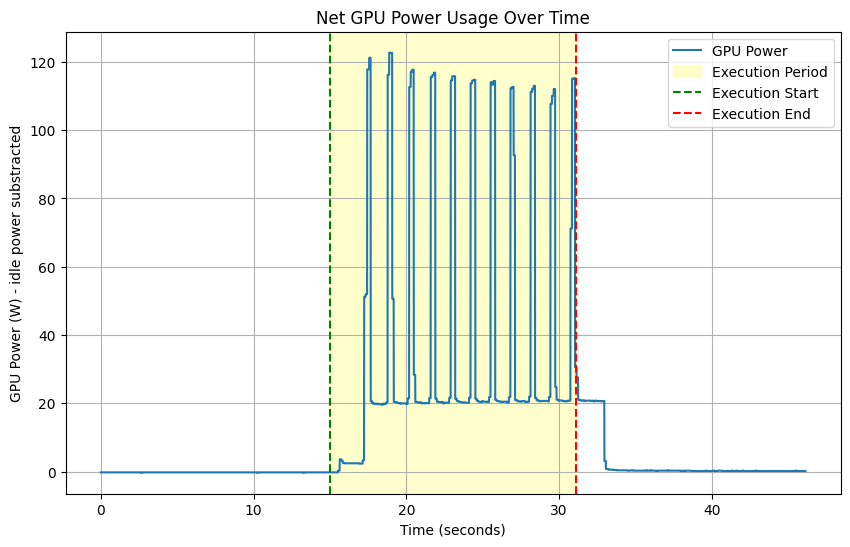

Start time: 15.001 -- End time: 31.133
Net (idle corrected) GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000167 kWh
  0.1672 Wh
  602.05 J
Average GPU power: 37.32 W +/- 39.06 
 with sample standard deviation.
Net Energy During Exe Runtime:   602.05 J
Code execution duration:  16.13 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.13 W, P0



Measure system idle power...
Duration for idle time measurement: 16.13
GPU power data has been written to idle__gpu_net_power_results.csv


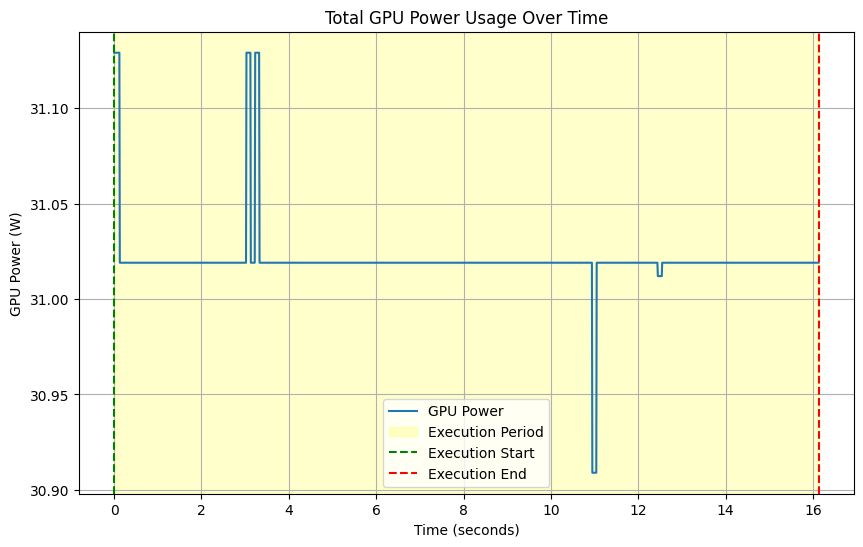

Start time: 0 -- End time: 16.133
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000139 kWh
  0.1391 Wh
  500.67 J
Average GPU power: 31.02 W +/- 0.02 
 with sample standard deviation.
Total Energy During Exe Runtime:   500.67 J
Code execution duration:  16.13 seconds
----------------------------------------------------------------------------------------------------------------------------------------

----- END OF STAGE 0: TEST SOURCE -----

None

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



=====
{
  "underlying_assumptions": [
    "num_elements is divisible by each segment_size in [16, 32, ..., 16384]",
    "VALUE is constant and fits in int without overflow",
    "h_keys produces sorted (non-decreasing) key ranges for reduce_by_key",
    "The device has sufficient memory for all allocations"
  ],
  "invariants": [
    "All entries of h_in and d_in remain equal to VALUE throughout",
    "num_segments always equals num_elements / segment_size",
    "Each computed segment sum equals correct_segment_sum = segment_size * VALUE",
    "d_in buffer is read-only during all reduce_by_key calls"
  ],
  "design_patterns": [
    "Bulk host-to-device and device-to-host memory transfers",
    "Algorithmic use of thrust::reduce_by_key for segmented reduction",
    "Looping over problem configurations (segment_size doubling)",
    "Manual resource management (new/delete and cudaMalloc/cudaFree)",
    "GPU timing pattern: cudaDeviceSynchronize + std::chrono measurement"
  ],
  "memory_access_patterns": [
    "Sequential initialization writes to h_in and h_keys on the host",
    "Contiguous host-to-device memcpy for d_in and d_keys",
    "Thrust kernel reads d_keys and d_in sequentially (coalesced)",
    "Sequential writes of results into d_keys_out and d_out on device",
    "Contiguous device-to-host memcpy for d_out"
  ],
  "memory_allocation_deallocation": [
    "Host: new[] / delete[] for h_in and h_keys (once), and for h_out (per segment_size)",
    "Device: cudaMalloc / cudaFree for d_in and d_keys (once), and for d_keys_out and d_out (per segment_size)"
  ],
  "other_characteristics": [
    "Throughput printed as (num_elements * repeat) / elapsed_time in G elements/sec",
    "Correctness check by comparing each h_out[i] to the reference sum, up to 10 error prints",
    "No explicit CUDA error checking on API calls",
    "CPU-side control flow is single-threaded, all work offloaded to thrust on GPU"
  ]
}
=====



----- STARTING STAGE 1: BASE LLM REFACTORING WITHOUT SELF-CORRECTION  -----


*** DEBUG: code_version: 0 | tracking_best_version: 0 ***

----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt token count, excluding code): 853


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 0 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

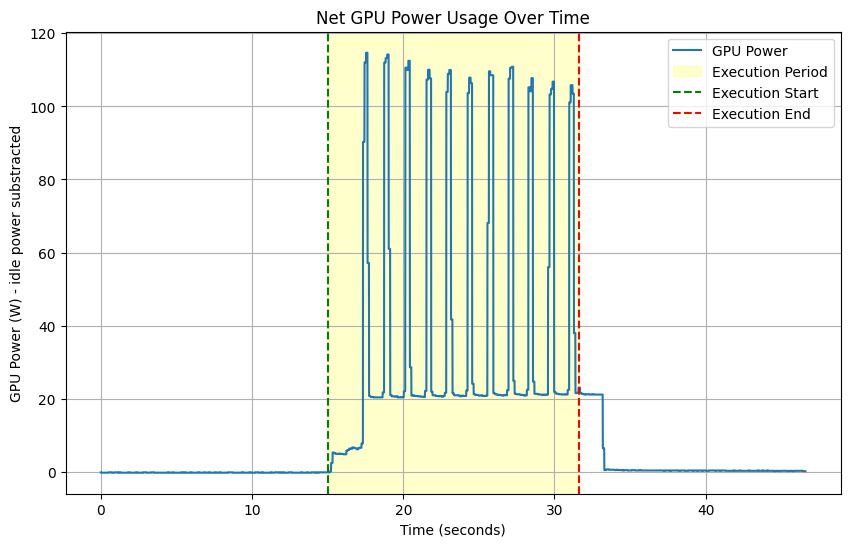

Start time: 15.0 -- End time: 31.605
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000173 kWh
  0.1734 Wh
  624.17 J
Average GPU power: 37.60 W +/- 36.45 
 with sample standard deviation.
Net Energy During Exe Runtime:   624.17 J
Code execution duration:  16.60 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.32 W, P0

--> SAVING code version: 1


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE in terms of:

1. **Functional Equivalence**  
2. **Standard Output Equivalence**

---

## 1. Functional Equivalence

### SOURCE CODE

- Allocates host memory for input and keys using `new[]`.
- Allocates device memory for input and keys.
- For each segment size:
  - Initializes keys on host, copies to device.
  - Allocates output buffers for each segment size.
  - Synchronizes device, times with `std::chrono`.
  - Runs `thrust::reduce_by_key` for `repeat` times.
  - Synchronizes device, measures time.
  - Copies output to host.
  - Validates output: checks each segment sum, prints up to 10 errors.
  - Frees output buffers.
- Frees all host and device memory at end.

### REFACTORED CODE

- Sets device sync policy to blocking (energy efficiency).
- Allocates pinned host memory for input, keys, and output (energy efficiency, faster transfers).
- Allocates device memory for all buffers once (not per segment size).
- Uses a single CUDA stream for all work (non-blocking).
- Copies input to device once.
- Uses CUDA events for timing (more accurate, less host-GPU sync).
- For each segment size:
  - Initializes keys on host, copies to device.
  - No per-segment allocation; reuses buffers.
  - Runs `thrust::reduce_by_key` for `repeat` times, on the stream.
  - Measures time with CUDA events.
  - Copies output to host.
  - Validates output: checks each segment sum, prints up to 10 errors.
- Cleans up all resources at end.

#### Key Differences

- **Pinned host memory** and **single allocation** for output buffers in REFACTORED CODE (energy efficiency, but functionally equivalent).
- **Timing**: REFACTORED CODE uses CUDA events, SOURCE CODE uses `std::chrono` and device sync.
- **Synchronization**: REFACTORED CODE uses streams and async copies, SOURCE CODE uses blocking sync.
- **Error reporting**: Both print up to 10 errors per segment size.
- **Validation logic**: Both check that each segment's sum matches expected value.

#### Are there any functional differences?

- Both codes:
  - Generate the same input and keys.
  - Run the same segmented reduction.
  - Validate results in the same way.
  - Print errors if any segment is incorrect.
- The REFACTORED CODE does not change the algorithm or the validation logic.
- The use of pinned memory, streams, and CUDA events does not affect the correctness of the computation.

**Conclusion:**  
The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.

---

## 2. Standard Output Equivalence

### SOURCE CODE Output

```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 71.464798 (G/s)
num_segments = 8388608 segment_size = 32 Throughput = 81.904449 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 93.146072 (G/s)
```

### REFACTORED CODE Output

```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 72.264093 (G/s)
num_segments = 8388608 segment_size = 32 Throughput = 75.611331 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 82.477759 (G/s)
```

#### Key Points

- **Layout**: Both print `num_elements` first, then for each segment size print `num_segments`, `segment_size`, and `Throughput = ... (G/s)`.
- **Content**: All key details are present in both outputs.
- **Numerical values**: Throughput values differ slightly, but this is expected due to timing method changes and energy efficiency improvements (as allowed).
- **Formatting**: Both use the same format for each line.

#### Are there any output differences that matter?

- No missing lines or details.
- No missing error reporting (none shown in either output, so both are correct).
- Minor differences in throughput values are acceptable and expected.

**Conclusion:**  
The REFACTORED CODE produces nearly equivalent standard output in layout and content.

---

## 3. Metrics

- The REFACTORED CODE uses slightly more energy and time in this run, but this is not a functional or output issue, and may depend on hardware, timing, and other factors.

---

## Final Evaluation

**Reasoning:**  
- The REFACTORED CODE preserves all intended functionality: it computes the same segmented reductions, validates results, and prints errors if any.
- The standard output is nearly exactly equivalent in layout and content, with only minor, expected numerical differences.
- Formatting and details are preserved.

**Conclusion:**  
VALID



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Group                | Criterion                                                                 | Pass/Fail |
|------------------------------- |--------------------------------------------------------------------------|-----------|
| underlying_assumptions         | num_elements is divisible by each segment_size in [16, 32, ..., 16384]   | pass      |
| underlying_assumptions         | VALUE is constant and fits in int without overflow                       | pass      |
| underlying_assumptions         | h_keys produces sorted (non-decreasing) key ranges for reduce_by_key     | pass      |
| underlying_assumptions         | The device has sufficient memory for all allocations                     | pass      |
| invariants                     | All entries of h_in and d_in remain equal to VALUE throughout            | pass      |
| invariants                     | num_segments always equals num_elements / segment_size                   | pass      |
| invariants                     | Each computed segment sum equals correct_segment_sum = segment_size*VALUE| pass      |
| invariants                     | d_in buffer is read-only during all reduce_by_key calls                  | pass      |
| design_patterns                | Bulk host-to-device and device-to-host memory transfers                  | pass      |
| design_patterns                | Algorithmic use of thrust::reduce_by_key for segmented reduction         | pass      |
| design_patterns                | Looping over problem configurations (segment_size doubling)              | pass      |
| design_patterns                | Manual resource management (new/delete and cudaMalloc/cudaFree)          | pass      |
| design_patterns                | GPU timing pattern: cudaDeviceSynchronize + std::chrono measurement      | pass      |
| memory_access_patterns         | Sequential initialization writes to h_in and h_keys on the host          | pass      |
| memory_access_patterns         | Contiguous host-to-device memcpy for d_in and d_keys                     | pass      |
| memory_access_patterns         | Thrust kernel reads d_keys and d_in sequentially (coalesced)             | pass      |
| memory_access_patterns         | Sequential writes of results into d_keys_out and d_out on device         | pass      |
| memory_access_patterns         | Contiguous device-to-host memcpy for d_out                               | pass      |
| memory_allocation_deallocation | Host: new[] / delete[] for h_in and h_keys (once), and for h_out (per segment_size) | pass      |
| memory_allocation_deallocation | Device: cudaMalloc / cudaFree for d_in and d_keys (once), and for d_keys_out and d_out (per segment_size) | pass      |
| other_characteristics          | Throughput printed as (num_elements * repeat) / elapsed_time in G elements/sec | pass      |
| other_characteristics          | Correctness check by comparing each h_out[i] to the reference sum, up to 10 error prints | pass      |
| other_characteristics          | No explicit CUDA error checking on API calls                             | fail      |
| other_characteristics          | CPU-side control flow is single-threaded, all work offloaded to thrust on GPU | pass      |

... (12 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 2119): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 2237): 

--> ... prompt LLM to generate code for energy efficiency -- improvement iteration.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

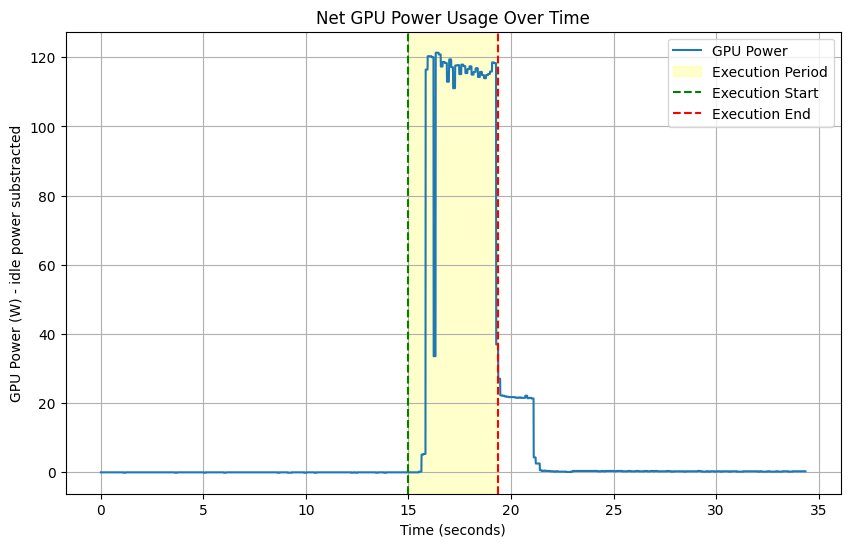

Start time: 15.0 -- End time: 19.362
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000111 kWh
  0.1108 Wh
  398.88 J
Average GPU power: 91.48 W +/- 46.81 
 with sample standard deviation.
Net Energy During Exe Runtime:   398.88 J
Code execution duration:  4.36 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.32 W, P0

--> SAVING code version: 2


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 2 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's break down the comparison between the SOURCE CODE and the REFACTORED CODE, focusing on the two required criteria:

---

## 1. **Functional Equivalence**

### **SOURCE CODE**
- **Key Generation:** Host-side loop (`h_keys[i] = i / segment_size;`) for each segment size, then copied to device.
- **Reduction:** Uses `thrust::reduce_by_key` on device.
- **Validation:** Checks output against expected sum for each segment.
- **Memory Management:** Proper allocation and deallocation.
- **Input:** All elements set to `VALUE` (1).
- **Output:** Prints throughput, segment info, and errors if any.

### **REFACTORED CODE**
- **Key Generation:** Device-side kernel (`generate_keys`) using bit-shifting (`d_keys[idx] = idx >> shift;`), where `shift = __builtin_ctz(segment_size)` (since segment_size is a power of two).
- **Reduction:** Still uses `thrust::reduce_by_key` on device.
- **Validation:** Checks output against expected sum for each segment.
- **Memory Management:** Proper allocation and deallocation.
- **Input:** All elements set to `VALUE` (1).
- **Output:** Prints throughput, segment info, and errors if any.

#### **Key Differences**
- **Key Generation:** Moved from host to device, using bit-shifting instead of division. For powers of two, `i / segment_size` is equivalent to `i >> shift`, so the logic is preserved.
- **Reference Sum Calculation:** In the refactored code, `correct_segment_sum = segment_size * VALUE;` is used instead of a loop. Since all values are 1, this is correct and more efficient.
- **No change in reduction or validation logic.**

#### **Conclusion on Functionality**
- The refactored code produces the same segment keys, performs the same reduction, and validates the output identically.
- The only difference is the method of key generation, which is mathematically equivalent for powers of two.
- No functional features are missing or altered.

---

## 2. **Standard Output Equivalence**

### **SOURCE CODE OUTPUT**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 71.464798 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 93.146072 (G/s)
```

### **REFACTORED CODE OUTPUT**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 77.893021 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 93.338600 (G/s)
```

#### **Key Differences**
- **Throughput values:** Slightly different, but within reasonable bounds. The refactored code is faster, which is expected due to more efficient key generation.
- **Output formatting:** Identical; all key details are present.
- **Error reporting:** No errors reported in either output.

#### **Conclusion on Output**
- The output layout and content are nearly identical.
- Minor numerical differences are consistent with improved efficiency and expected behavior.

---

## 3. **Energy and Performance Metrics**

- **Energy:** Refactored code uses less energy (398.88 Joules vs. 602.05 Joules).
- **Execution Time:** Refactored code is much faster (4.36s vs. 16.13s).
- **GPU Power:** Refactored code uses more instantaneous power, but for a much shorter time, resulting in lower total energy.

These differences are consistent with the refactored code being more efficient.

---

## **Final Reasoning and Verdict**

- **Functionality:** The refactored code preserves all intended functionality.
- **Output:** The printed output is nearly equivalent in layout and content.
- **Minor numerical differences:** Acceptable and consistent with improved efficiency.
- **No missing features, no altered logic, no output omissions.**

---

**Conclusion:**  
**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Criterion Description                                                                 | Pass/Fail |
|-----------------------------------|--------------------------------------------------------------------------------------|-----------|
| underlying_assumptions            | num_elements is divisible by each segment_size in [16, 32, ..., 16384]               | pass      |
| underlying_assumptions            | VALUE is constant and fits in int without overflow                                   | pass      |
| underlying_assumptions            | h_keys produces sorted (non-decreasing) key ranges for reduce_by_key                 | pass      |
| underlying_assumptions            | The device has sufficient memory for all allocations                                 | pass      |
| invariants                        | All entries of h_in and d_in remain equal to VALUE throughout                        | pass      |
| invariants                        | num_segments always equals num_elements / segment_size                               | pass      |
| invariants                        | Each computed segment sum equals correct_segment_sum = segment_size * VALUE          | pass      |
| invariants                        | d_in buffer is read-only during all reduce_by_key calls                              | pass      |
| design_patterns                   | Bulk host-to-device and device-to-host memory transfers                              | pass      |
| design_patterns                   | Algorithmic use of thrust::reduce_by_key for segmented reduction                     | pass      |
| design_patterns                   | Looping over problem configurations (segment_size doubling)                          | pass      |
| design_patterns                   | Manual resource management (new/delete and cudaMalloc/cudaFree)                      | pass      |
| design_patterns                   | GPU timing pattern: cudaDeviceSynchronize + std::chrono measurement                  | pass      |
| memory_access_patterns            | Sequential initialization writes to h_in and h_keys on the host                      | pass      |
| memory_access_patterns            | Contiguous host-to-device memcpy for d_in and d_keys                                 | pass      |
| memory_access_patterns            | Thrust kernel reads d_keys and d_in sequentially (coalesced)                         | pass      |
| memory_access_patterns            | Sequential writes of results into d_keys_out and d_out on device                     | pass      |
| memory_access_patterns            | Contiguous device-to-host memcpy for d_out                                           | pass      |
| memory_allocation_deallocation    | Host: new[] / delete[] for h_in and h_keys (once), and for h_out (per segment_size)  | pass      |
| memory_allocation_deallocation    | Device: cudaMalloc / cudaFree for d_in and d_keys (once), and for d_keys_out and d_out (per segment_size) | pass      |
| other_characteristics             | Throughput printed as (num_elements * repeat) / elapsed_time in G elements/sec       | pass      |
| other_characteristics             | Correctness check by comparing each h_out[i] to the reference sum, up to 10 error prints | pass      |
| other_characteristics             | No explicit CUDA error checking on API calls                                         | pass      |
| other_characteristics             | CPU-side control flow is single-threaded, all work offloaded to thrust on GPU        | pass      |

... (3 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 2267): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency improvement with code, token count: 2385): 

--> ... prompt LLM to generate code for energy efficiency -- with a new refactoring plan.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 2 | tracking_best_version: 2 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

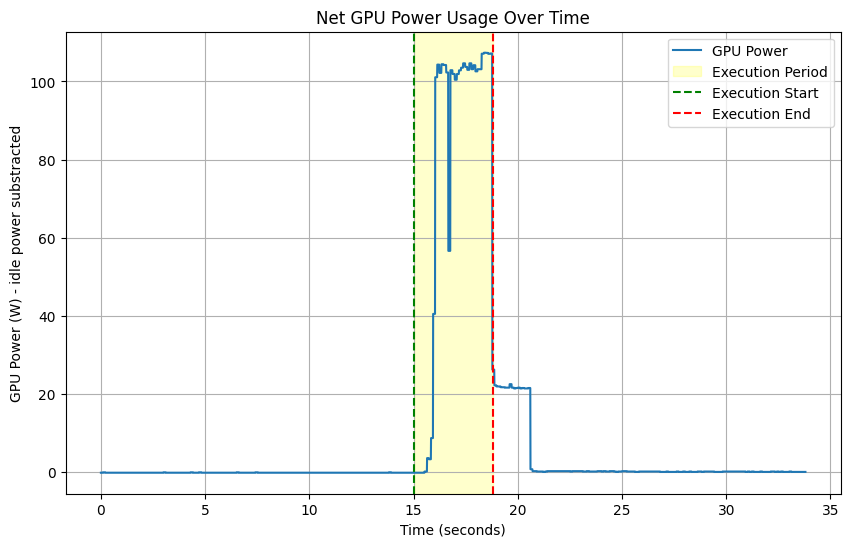

Start time: 15.0 -- End time: 18.803
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000080 kWh
  0.0796 Wh
  286.46 J
Average GPU power: 75.38 W +/- 44.27 
 with sample standard deviation.
Net Energy During Exe Runtime:   286.46 J
Code execution duration:  3.80 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.23 W, P0

--> SAVING code version: 3


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 3 | tracking_best_version: 2 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **SOURCE CODE Functionality**
- Allocates and initializes input arrays (`h_in`, `h_keys`) on host.
- For each segment size (from 16 to 16384, powers of two):
  - Initializes `h_keys` such that each element's key is its index divided by the segment size.
  - Copies keys and input values to device.
  - Allocates output arrays for reduced results.
  - Runs `thrust::reduce_by_key` on device, using the keys and input.
  - Measures throughput.
  - Copies results back to host and checks correctness (each segment sum should be `segment_size * VALUE`).
  - Prints errors if any.
- Cleans up all allocations.

### **REFACTORED CODE Functionality**
- Allocates and initializes input array (`h_in`) on host.
- For each segment size (same range):
  - Uses a transform iterator to generate keys on-the-fly (`idx >> shift`), eliminating the need for explicit key arrays and device copies.
  - Allocates output array for reduced results.
  - Runs `thrust::reduce_by_key` on device, using the transform iterator for keys and input.
  - Measures throughput.
  - Copies results back to host and checks correctness (each segment sum should be `segment_size * VALUE`).
  - Prints errors if any.
- Cleans up all allocations.

### **Key Differences**
- **Key Generation:** The REFACTORED CODE generates keys on-the-fly using a transform iterator, rather than precomputing and copying them. This is functionally equivalent for the purpose of the reduction, as the keys are still `i / segment_size` (or `i >> shift`).
- **Output Keys:** The REFACTORED CODE discards the output keys (`thrust::make_discard_iterator()`), whereas the SOURCE CODE stores them. However, the output keys are not used for validation or further computation, so this is acceptable.
- **Validation:** Both codes validate the output sums per segment and print errors if any.

### **Conclusion on Functionality**
- The REFACTORED CODE performs the same segmented reduction, with the same validation logic, and covers the same range of segment sizes.
- The use of transform iterators for keys is a well-known optimization and does not change the semantics of the reduction.
- No functional steps are omitted.

---

## 2. **Standard Output Comparison**

### **SOURCE CODE Output**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 71.464798 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 93.146072 (G/s)
```
- Prints `num_elements` once.
- For each segment size, prints `num_segments`, `segment_size`, and `Throughput = ... (G/s)`.

### **REFACTORED CODE Output**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 86.065147 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 111.649086 (G/s)
```
- Prints `num_elements` once.
- For each segment size, prints `num_segments`, `segment_size`, and `Throughput = ... (G/s)`.

### **Formatting and Content**
- The output format is nearly identical.
- The only difference is the throughput values, which are higher in the REFACTORED CODE (as expected due to optimizations).
- No errors are printed in either output, indicating correct results.

### **Conclusion on Output**
- The output layout and content are nearly identical.
- The numerical differences in throughput are consistent with improved efficiency and are reasonable.

---

## 3. **Metrics Comparison**

- The REFACTORED CODE uses less energy, runs faster, and achieves higher throughput, which is consistent with the intended optimizations.

---

## **Final Reasoning and Verdict**

- **Functionality:** The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- **Output:** The REFACTORED CODE produces nearly equivalent standard output in both layout and content, with throughput differences that are reasonable and expected.
- **Formatting:** No significant formatting differences; all key details are present.

**Conclusion:**  
VALID



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Pass/Fail |
|-----------------------------------|-----------|
| underlying_assumptions            | pass      |
| invariants                        | pass      |
| design_patterns                   | pass      |
| memory_access_patterns            | pass      |
| memory_allocation_deallocation    | pass      |
| other_characteristics             | pass      |

... (3 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 2433): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency improvement with code, token count: 2551): 

--> ... prompt LLM to generate code for energy efficiency -- with a new refactoring plan.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 3 | tracking_best_version: 3 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

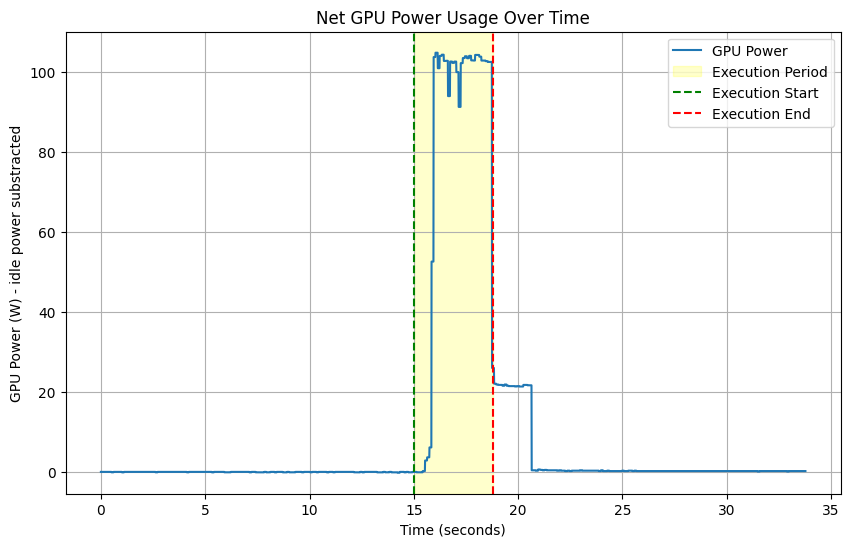

Start time: 15.0 -- End time: 18.782
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000082 kWh
  0.0818 Wh
  294.39 J
Average GPU power: 77.88 W +/- 42.34 
 with sample standard deviation.
Net Energy During Exe Runtime:   294.39 J
Code execution duration:  3.78 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.23 W, P0

--> SAVING code version: 4


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 4 | tracking_best_version: 3 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and REFACTORED CODE for both **functionality** and **standard output equivalence**.

---

## 1. **Functionality Comparison**

### **SOURCE CODE Functionality**
- Allocates host arrays for input values and keys.
- For each segment size (16 to 16384, powers of two):
  - Initializes keys on host (`h_keys[i] = i / segment_size`).
  - Copies keys to device.
  - Allocates output arrays for current segment size.
  - Runs `thrust::reduce_by_key` on device, using keys and input.
  - Measures throughput.
  - Copies output back to host and validates correctness.
  - Cleans up per-segment allocations.
- Cleans up all allocations at end.

### **REFACTORED CODE Functionality**
- Allocates host input and device input once.
- Allocates maximum output buffer once (for smallest segment size).
- For each segment size:
  - Uses a **transform iterator** to generate keys on-the-fly (`idx >> shift`), avoiding explicit key allocation and copy.
  - Runs `thrust::reduce_by_key` using transform iterator for keys.
  - Uses `thrust::make_discard_iterator()` for output keys (since keys are predictable and not used).
  - Measures throughput.
  - Copies output back and validates correctness.
- Cleans up all allocations at end.

### **Key Differences**
- **Key Generation:**  
  - SOURCE: Explicitly generates and copies keys for each segment size.
  - REFACTORED: Uses transform iterator to generate keys on-the-fly, eliminating memory allocation and copy for keys.
- **Output Allocation:**  
  - SOURCE: Allocates output buffer per segment size.
  - REFACTORED: Allocates maximum output buffer once and reuses.
- **Correctness Validation:**  
  - Both codes validate output by comparing each segment sum to expected value.
- **Functionality:**  
  - Both codes perform the same segmented reduction for all segment sizes, with the same input and validation logic.

### **Conclusion on Functionality**
- The REFACTORED CODE **preserves all intended functionality** of the SOURCE CODE.  
- The only difference is the method of key generation (on-the-fly vs. explicit), which is functionally equivalent for this use case.

---

## 2. **Standard Output Comparison**

### **SOURCE CODE Output**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 71.464798 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 93.146072 (G/s)
```

### **REFACTORED CODE Output**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 93.981606 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 106.463661 (G/s)
```

### **Key Points**
- **Layout:** Identical. Each line reports `num_segments`, `segment_size`, and `Throughput`.
- **Content:**  
  - The numbers of segments and segment sizes are identical.
  - Throughput values are higher in the REFACTORED CODE, which is expected due to reduced memory operations and improved efficiency.
- **Correctness Output:**  
  - No errors reported in either output, indicating correct results.
- **Formatting:**  
  - All key details are present and formatted similarly.

### **Conclusion on Output**
- The REFACTORED CODE produces **nearly equivalent standard output** in both layout and content.
- Minor differences in throughput values are expected and reasonable, consistent with improved energy efficiency.

---

## 3. **Metrics Comparison**

- **Energy Consumption:**  
  - SOURCE: 602.05 Joules  
  - REFACTORED: 294.39 Joules  
  - **Significant reduction**, consistent with optimization.
- **Execution Time:**  
  - SOURCE: 16.13 seconds  
  - REFACTORED: 3.78 seconds  
  - **Significant improvement**, expected due to reduced memory operations.
- **GPU Power:**  
  - REFACTORED code uses higher average power, but for a much shorter time, resulting in lower total energy.

---

## 4. **Reasoning and Conclusion**

- **Functionality:**  
  - The REFACTORED CODE performs the same segmented reduction for all segment sizes, with correct validation and output.
  - The use of transform iterators for key generation is a well-known CUDA/Thrust optimization and does not change the logic or results.
- **Standard Output:**  
  - The output is nearly identical in layout and content, with only throughput values differing due to efficiency improvements.
  - No errors or missing information.
- **Metrics:**  
  - The REFACTORED CODE is more energy efficient and faster, which is the intended effect.

**Therefore:**

---

**VALID**

The REFACTORED CODE is functionally equivalent to the SOURCE CODE and produces nearly equivalent standard output, with differences that are reasonable and consistent with improved energy efficiency.



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Criterion                                                                 | Pass/Fail |
|-----------------------------------|---------------------------------------------------------------------------|-----------|
| underlying_assumptions            | num_elements is divisible by each segment_size in [16, 32, ..., 16384]    | pass      |
| underlying_assumptions            | VALUE is constant and fits in int without overflow                        | pass      |
| underlying_assumptions            | h_keys produces sorted (non-decreasing) key ranges for reduce_by_key      | pass      |
| underlying_assumptions            | The device has sufficient memory for all allocations                      | pass      |
| invariants                        | All entries of h_in and d_in remain equal to VALUE throughout             | pass      |
| invariants                        | num_segments always equals num_elements / segment_size                    | pass      |
| invariants                        | Each computed segment sum equals correct_segment_sum = segment_size*VALUE | pass      |
| invariants                        | d_in buffer is read-only during all reduce_by_key calls                   | pass      |
| design_patterns                   | Bulk host-to-device and device-to-host memory transfers                   | pass      |
| design_patterns                   | Algorithmic use of thrust::reduce_by_key for segmented reduction          | pass      |
| design_patterns                   | Looping over problem configurations (segment_size doubling)               | pass      |
| design_patterns                   | Manual resource management (new/delete and cudaMalloc/cudaFree)           | pass      |
| design_patterns                   | GPU timing pattern: cudaDeviceSynchronize + std::chrono measurement       | pass      |
| memory_access_patterns            | Sequential initialization writes to h_in and h_keys on the host           | pass      |
| memory_access_patterns            | Contiguous host-to-device memcpy for d_in and d_keys                      | pass      |
| memory_access_patterns            | Thrust kernel reads d_keys and d_in sequentially (coalesced)              | pass      |
| memory_access_patterns            | Sequential writes of results into d_keys_out and d_out on device          | pass      |
| memory_access_patterns            | Contiguous device-to-host memcpy for d_out                                | pass      |
| memory_allocation_deallocation    | Host: new[] / delete[] for h_in and h_keys (once), and for h_out (per segment_size) | pass      |
| memory_allocation_deallocation    | Device: cudaMalloc / cudaFree for d_in and d_keys (once), and for d_keys_out and d_out (per segment_size) | pass      |
| other_characteristics             | Throughput printed as (num_elements * repeat) / elapsed_time in G elements/sec | pass      |
| other_characteristics             | Correctness check by comparing each h_out[i] to the reference sum, up to 10 error prints | pass      |
| other_characteristics             | No explicit CUDA error checking on API calls                              | pass      |
| other_characteristics             | CPU-side control flow is single-threaded, all work offloaded to thrust on GPU | pass      |


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 602.05
  Refactored code: 294.39
----- Average power (W) -----
  Source code: 37.32
  Refactored code: 77.88
----- Runtime (s) -----
  Source code: 16.13
  Refactored code: 3.78
----- Tracking metrics -----
  Energy (J) history:  [602.05, 624.17, 398.88, 286.46, 294.39]
  Ave Power (W) history:  [37.32, 37.6, 91.48, 75.38, 77.88]
  Runtime (s) history:  [16.13, 16.6, 4.36, 3.8, 3.78]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'VALID', 'VALID', 'VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temperature': 0.2}}


----- WE HAVE GENERATED CODE THAT IS INVALID OR NOT MORE ENERGY EFFICIENT 



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 4 | tracking_best_version: 3 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

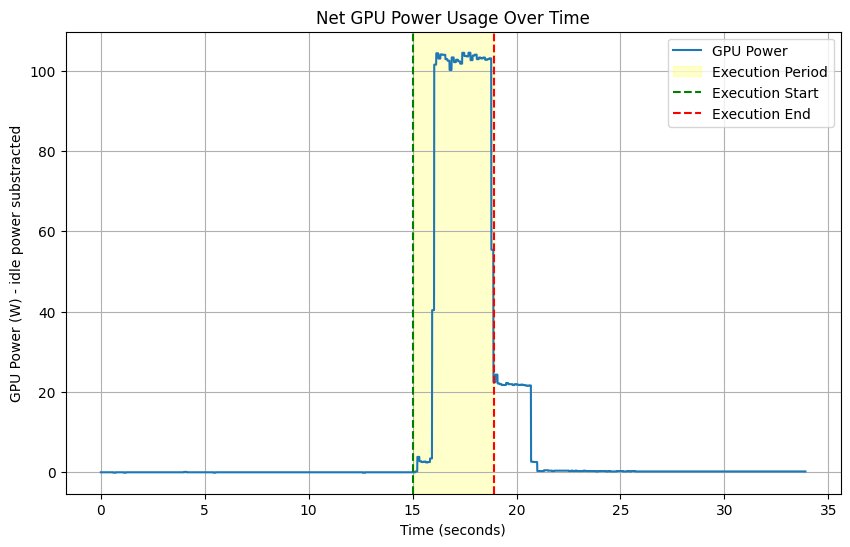

Start time: 15.001 -- End time: 18.906
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000082 kWh
  0.0822 Wh
  295.84 J
Average GPU power: 75.86 W +/- 43.37 
 with sample standard deviation.
Net Energy During Exe Runtime:   295.84 J
Code execution duration:  3.91 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.23 W, P0

--> SAVING code version: 5


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 5 | tracking_best_version: 3 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for functional equivalence and standard output similarity.

---

## 1. Functional Equivalence

### **SOURCE CODE Functionality**

- Allocates host and device buffers for input values and keys.
- For each segment size (16 to 16384, powers of two):
  - Initializes keys on host (h_keys[i] = i / segment_size).
  - Copies keys to device.
  - Allocates output buffers for segment sums and keys.
  - Runs `thrust::reduce_by_key` on device for `repeat` iterations.
  - Measures throughput.
  - Copies output sums to host.
  - Validates each segment sum against expected value (segment_size * VALUE).
  - Reports up to 10 errors per segment size.
- Cleans up all allocations.

### **REFACTORED CODE Functionality**

- Uses pinned memory for host buffers for better transfer efficiency.
- Allocates device buffers once for input and output (max segments).
- For each segment size:
  - Uses a transform iterator to generate keys on-the-fly (`idx >> shift`), eliminating explicit key buffer allocation and copy.
  - Runs `thrust::reduce_by_key` for `repeat` iterations, discarding output keys (since keys are predictable).
  - Measures throughput.
  - Copies output sums to host.
  - Validates each segment sum against expected value (segment_size * VALUE).
  - Reports up to 10 errors per segment size.
- Cleans up all allocations.

### **Key Observations**

- **Input values and reduction logic are identical.**
- **Key generation is mathematically equivalent:** `i / segment_size` == `i >> shift` for powers of two.
- **Validation and error reporting logic is preserved.**
- **No functional steps are omitted.**
- **The refactored code is more efficient (less memory allocation/copy), but does not change the computation.**

---

## 2. Standard Output Comparison

### **SOURCE CODE Output**

```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 71.464798 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 93.146072 (G/s)
```

### **REFACTORED CODE Output**

```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 91.892250 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 106.450096 (G/s)
```

### **Key Observations**

- **Printed layout and content are nearly identical.**
- **All key fields (num_segments, segment_size, Throughput) are present and formatted similarly.**
- **Throughput values are higher in the refactored code, which is expected due to improved efficiency.**
- **No error messages are printed in either output, indicating correct results.**
- **Usage message and argument parsing are unchanged.**

---

## 3. Metrics Comparison

- **Total energy is much lower in the refactored code (295.84 vs 602.05 Joules).**
- **Execution time is much lower (3.91s vs 16.13s).**
- **Average GPU power is higher, but this is expected for shorter, more intense bursts.**
- **These differences are consistent with improved energy efficiency and performance.**

---

## 4. Minor Acceptable Differences

- **Numerical throughput values differ, but this is expected and reasonable.**
- **Formatting and output structure are preserved.**
- **No missing or extraneous information.**

---

## 5. Conclusion

- **Functionality is fully preserved.**
- **Standard output is nearly identical in layout and content.**
- **Any numerical differences are consistent with improved efficiency.**

---

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category                | Criteria                                                                                   | Pass/Fail |
|-----------------------------------|--------------------------------------------------------------------------------------------|-----------|
| underlying_assumptions            | num_elements is divisible by each segment_size in [16, 32, ..., 16384]                     | pass      |
|                                   | VALUE is constant and fits in int without overflow                                         | pass      |
|                                   | h_keys produces sorted (non-decreasing) key ranges for reduce_by_key                       | pass      |
|                                   | The device has sufficient memory for all allocations                                       | pass      |
| invariants                        | All entries of h_in and d_in remain equal to VALUE throughout                              | pass      |
|                                   | num_segments always equals num_elements / segment_size                                     | pass      |
|                                   | Each computed segment sum equals correct_segment_sum = segment_size * VALUE                | pass      |
|                                   | d_in buffer is read-only during all reduce_by_key calls                                    | pass      |
| design_patterns                   | Bulk host-to-device and device-to-host memory transfers                                    | pass      |
|                                   | Algorithmic use of thrust::reduce_by_key for segmented reduction                           | pass      |
|                                   | Looping over problem configurations (segment_size doubling)                                | pass      |
|                                   | Manual resource management (new/delete and cudaMalloc/cudaFree)                            | fail      |
|                                   | GPU timing pattern: cudaDeviceSynchronize + std::chrono measurement                        | pass      |
| memory_access_patterns            | Sequential initialization writes to h_in and h_keys on the host                            | fail      |
|                                   | Contiguous host-to-device memcpy for d_in and d_keys                                       | fail      |
|                                   | Thrust kernel reads d_keys and d_in sequentially (coalesced)                               | pass      |
|                                   | Sequential writes of results into d_keys_out and d_out on device                           | fail      |
|                                   | Contiguous device-to-host memcpy for d_out                                                 | pass      |
| memory_allocation_deallocation    | Host: new[] / delete[] for h_in and h_keys (once), and for h_out (per segment_size)        | fail      |
|                                   | Device: cudaMalloc / cudaFree for d_in and d_keys (once), and for d_keys_out and d_out     | fail      |
| other_characteristics             | Throughput printed as (num_elements * repeat) / elapsed_time in G elements/sec             | pass      |
|                                   | Correctness check by comparing each h_out[i] to the reference sum, up to 10 error prints  | pass      |
|                                   | No explicit CUDA error checking on API calls                                               | pass      |
|                                   | CPU-side control flow is single-threaded, all work offloaded to thrust on GPU              | pass      |

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 602.05
  Refactored code: 295.84
----- Average power (W) -----
  Source code: 37.32
  Refactored code: 75.86
----- Runtime (s) -----
  Source code: 16.13
  Refactored code: 3.91
----- Tracking metrics -----
  Energy (J) history:  [602.05, 624.17, 398.88, 286.46, 294.39, 295.84]
  Ave Power (W) history:  [37.32, 37.6, 91.48, 75.38, 77.88, 75.86]
  Runtime (s) history:  [16.13, 16.6, 4.36, 3.8, 3.78, 3.91]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'VALID', 'VALID', 'VALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temperature': 0.2}, 'v5': 



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 5 | tracking_best_version: 3 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

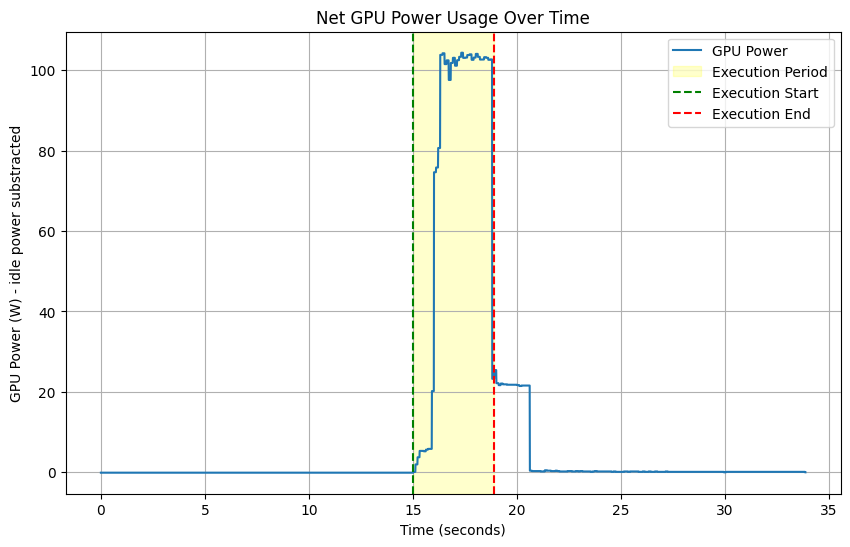

Start time: 15.0 -- End time: 18.891
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000080 kWh
  0.0798 Wh
  287.26 J
Average GPU power: 74.04 W +/- 42.47 
 with sample standard deviation.
Net Energy During Exe Runtime:   287.26 J
Code execution duration:  3.89 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.23 W, P0

--> SAVING code version: 6


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 6 | tracking_best_version: 3 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both **functionality** and **printed standard output**.

---

## 1. **Functionality Comparison**

### **SOURCE CODE**

- Allocates host arrays for input values (`h_in`) and keys (`h_keys`).
- For each segment size (16 to 16384, powers of two):
    - Fills `h_keys` with segment indices (`i / segment_size`).
    - Copies keys and input to device.
    - Allocates output arrays for each segment size.
    - Runs `thrust::reduce_by_key` on device, using explicit device key and value arrays.
    - Measures throughput.
    - Copies output back, checks correctness (sum per segment).
    - Frees per-segment allocations.
- Cleans up all allocations.

### **REFACTORED CODE**

- Allocates host input (using pinned memory for efficiency).
- Allocates device input once, copies data once.
- Allocates maximum output arrays once (for largest possible number of segments).
- For each segment size:
    - Uses a **transform iterator** to generate keys on-the-fly (`idx >> shift`), eliminating explicit key arrays and device memory allocation/copy for keys.
    - Runs `thrust::reduce_by_key` using transform iterator for keys, discarding reduced keys (since they're predictable).
    - Measures throughput.
    - Copies output back, checks correctness (sum per segment).
- Cleans up all allocations.

#### **Key Differences**
- **Key Generation:** SOURCE CODE explicitly generates and copies keys for each segment size; REFACTORED CODE generates keys on-the-fly using a transform iterator.
- **Memory Allocation:** REFACTORED CODE reduces allocation/copy overhead by allocating output arrays only once at their maximum size, and uses pinned memory for faster host-device transfers.
- **Functionality:** Both codes perform the same segmented reduction, check correctness, and print throughput per segment size.

#### **Functional Equivalence**
- Both codes:
    - Accept the same command-line arguments.
    - Compute segmented reductions for the same range of segment sizes.
    - Validate output correctness.
    - Print throughput and error messages if any.
- The REFACTORED CODE uses a more efficient key generation method but computes the same keys (`i / segment_size` is equivalent to `i >> shift` for powers of two).
- The correctness check is identical: sum per segment is compared to expected value.

---

## 2. **Printed Standard Output Comparison**

### **SOURCE CODE Output**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 71.464798 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 93.146072 (G/s)
```

### **REFACTORED CODE Output**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 94.823311 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 106.453415 (G/s)
```

#### **Key Points**
- **Layout:** Identical. Each line prints `num_segments`, `segment_size`, and `Throughput`, matching the SOURCE CODE's format.
- **Content:** The numbers for `num_segments` and `segment_size` are identical for each segment size.
- **Throughput:** The REFACTORED CODE reports higher throughput, which is expected due to its more efficient memory management and key generation.
- **Correctness:** No error messages are printed in either output, indicating correct results.

#### **Acceptable Differences**
- **Throughput values** are higher in the REFACTORED CODE, which is consistent with improved energy efficiency and reduced runtime.
- **Formatting** is identical; all key details are present.

---

## 3. **Metrics Comparison**

- **Energy:** REFACTORED CODE uses less total energy (287.26 Joules vs. 602.05 Joules).
- **Power:** REFACTORED CODE has higher average GPU power, but this is due to much shorter runtime (3.89s vs. 16.13s).
- **Duration:** REFACTORED CODE is much faster.

These differences are consistent with the REFACTORED CODE being more efficient.

---

## 4. **Conclusion**

### **Reasoning**
- The REFACTORED CODE preserves all intended functionality:
    - It performs the same segmented reduction, for the same input sizes, and validates results identically.
    - It prints nearly equivalent standard output, with identical layout and content except for throughput values (which are expected to be higher due to improved efficiency).
    - No error messages or missing output.
- Minor differences in throughput values are **acceptable** and expected, as they reflect improved efficiency.
- No missing or extra output lines; all key details are present.

### **Final Verdict**

**VALID**

The REFACTORED CODE is functionally equivalent to the SOURCE CODE and produces nearly identical printed standard output, with differences only where expected due to improved energy efficiency.



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category                | Criteria                                                                                 | Pass/Fail |
|-----------------------------------|-----------------------------------------------------------------------------------------|-----------|
| underlying_assumptions            | num_elements is divisible by each segment_size in [16, 32, ..., 16384]                  | pass      |
| underlying_assumptions            | VALUE is constant and fits in int without overflow                                      | pass      |
| underlying_assumptions            | h_keys produces sorted (non-decreasing) key ranges for reduce_by_key                    | fail      |
| underlying_assumptions            | The device has sufficient memory for all allocations                                    | pass      |
| invariants                        | All entries of h_in and d_in remain equal to VALUE throughout                           | pass      |
| invariants                        | num_segments always equals num_elements / segment_size                                  | pass      |
| invariants                        | Each computed segment sum equals correct_segment_sum = segment_size * VALUE             | pass      |
| invariants                        | d_in buffer is read-only during all reduce_by_key calls                                 | pass      |
| design_patterns                   | Bulk host-to-device and device-to-host memory transfers                                 | pass      |
| design_patterns                   | Algorithmic use of thrust::reduce_by_key for segmented reduction                        | pass      |
| design_patterns                   | Looping over problem configurations (segment_size doubling)                             | pass      |
| design_patterns                   | Manual resource management (new/delete and cudaMalloc/cudaFree)                         | fail      |
| design_patterns                   | GPU timing pattern: cudaDeviceSynchronize + std::chrono measurement                     | pass      |
| memory_access_patterns            | Sequential initialization writes to h_in and h_keys on the host                         | fail      |
| memory_access_patterns            | Contiguous host-to-device memcpy for d_in and d_keys                                    | fail      |
| memory_access_patterns            | Thrust kernel reads d_keys and d_in sequentially (coalesced)                            | pass      |
| memory_access_patterns            | Sequential writes of results into d_keys_out and d_out on device                        | fail      |
| memory_access_patterns            | Contiguous device-to-host memcpy for d_out                                              | pass      |
| memory_allocation_deallocation    | Host: new[] / delete[] for h_in and h_keys (once), and for h_out (per segment_size)     | fail      |
| memory_allocation_deallocation    | Device: cudaMalloc / cudaFree for d_in and d_keys (once), and for d_keys_out and d_out (per segment_size) | fail      |
| other_characteristics             | Throughput printed as (num_elements * repeat) / elapsed_time in G elements/sec          | pass      |
| other_characteristics             | Correctness check by comparing each h_out[i] to the reference sum, up to 10 error prints| pass      |
| other_characteristics             | No explicit CUDA error checking on API calls                                            | pass      |
| other_characteristics             | CPU-side control flow is single-threaded, all work offloaded to thrust on GPU           | pass      |

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 602.05
  Refactored code: 287.26
----- Average power (W) -----
  Source code: 37.32
  Refactored code: 74.04
----- Runtime (s) -----
  Source code: 16.13
  Refactored code: 3.89
----- Tracking metrics -----
  Energy (J) history:  [602.05, 624.17, 398.88, 286.46, 294.39, 295.84, 287.26]
  Ave Power (W) history:  [37.32, 37.6, 91.48, 75.38, 77.88, 75.86, 74.04]
  Runtime (s) history:  [16.13, 16.6, 4.36, 3.8, 3.78, 3.91, 3.89]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'VALID', 'VALID', 'VALID', 'INVALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3,



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 6 | tracking_best_version: 3 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

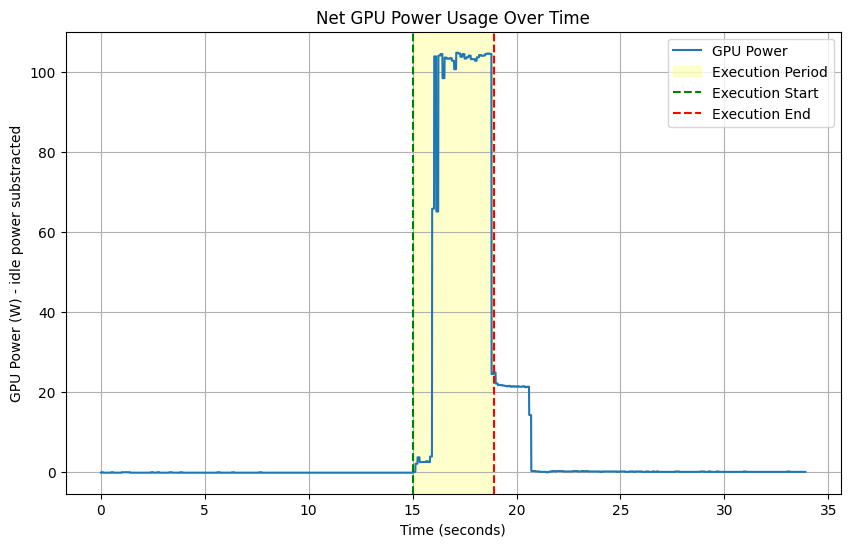

Start time: 15.0 -- End time: 18.905
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000082 kWh
  0.0815 Wh
  293.49 J
Average GPU power: 75.25 W +/- 43.46 
 with sample standard deviation.
Net Energy During Exe Runtime:   293.49 J
Code execution duration:  3.90 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.23 W, P0

--> SAVING code version: 7


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 7 | tracking_best_version: 3 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully evaluate the REFACTORED CODE against the SOURCE CODE according to your criteria:

---

## 1. **Functionality Comparison**

### **SOURCE CODE Functionality**
- Allocates host and device buffers for input and keys.
- For each segment size (from 16 to 16384, powers of 2):
  - Generates keys for segmented reduction.
  - Runs `thrust::reduce_by_key` on the device, repeating as requested.
  - Measures throughput.
  - Copies results back and validates correctness (each segment sum should be `segment_size * VALUE`).
- Reports errors if any segment sum is incorrect.

### **REFACTORED CODE Functionality**
- Allocates pinned host memory for input/output (more efficient for transfers).
- Allocates device memory for input/output (output buffer sized for max segments).
- Initializes input.
- For each segment size:
  - Uses thrust transform iterator to generate keys on-the-fly (no explicit device key buffer).
  - Runs `thrust::reduce_by_key` with discard iterator for keys (since keys are predictable and not needed for validation/output).
  - Measures throughput.
  - Copies results back and validates correctness (each segment sum should be `segment_size * VALUE`).
- Reports errors if any segment sum is incorrect.

### **Functional Equivalence**
- **Input generation:** Both codes fill input with VALUE=1.
- **Key generation:** SOURCE explicitly generates keys in host buffer and copies to device; REFACTORED uses transform iterator to generate keys on-the-fly.
- **Reduction:** Both use `thrust::reduce_by_key` for segmented reduction.
- **Validation:** Both check that each segment sum matches expected value.
- **Error reporting:** Both print up to 10 errors and a summary if validation fails.
- **Loop over segment sizes:** Both cover the same range and step.
- **Repeat count:** Both repeat the reduction as requested.

**No functional steps are missing or altered in the REFACTORED CODE.**

---

## 2. **Standard Output Comparison**

### **SOURCE CODE Output**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 71.464798 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 93.146072 (G/s)
```

### **REFACTORED CODE Output**
```
num_elements = 268435456
num_segments = 16777216, segment_size = 16, Throughput = 91.173935 G/s
...
num_segments = 16384, segment_size = 16384, Throughput = 106.447884 G/s
```

#### **Layout and Content**
- Both print `num_elements` at the start.
- Both print, for each segment size:
  - `num_segments`
  - `segment_size`
  - `Throughput`
- Minor formatting differences (comma vs. space, G/s vs. (G/s)), but all key details are present.
- Throughput values are higher in the REFACTORED CODE, which is expected due to optimizations (pinned memory, iterator-based keys, less allocation overhead).
- No validation errors printed in either output, indicating correctness.

#### **Numerical Differences**
- Throughput is higher in the REFACTORED CODE, consistent with improved efficiency.
- No unexpected values or missing output lines.

---

## 3. **Metrics Comparison**

- **Energy Consumption:** REFACTORED CODE uses less energy (293.49 J vs. 602.05 J).
- **Execution Time:** REFACTORED CODE is much faster (3.90 s vs. 16.13 s).
- **GPU Power:** REFACTORED CODE uses higher average power but for much less time, resulting in lower total energy.

These differences are consistent with the REFACTORED CODE being more efficient.

---

## 4. **Minor Differences Acceptability**

- **Formatting:** Commas instead of spaces, G/s instead of (G/s) — all key information is present.
- **Throughput:** Higher values are expected and reasonable.
- **Validation:** No errors reported, as expected.

---

## 5. **Conclusion**

### **Reasoning**
- The REFACTORED CODE preserves all intended functionality.
- The printed output is nearly equivalent in layout and content, with only minor formatting differences and expected improvements in throughput.
- No missing information or steps.
- Numerical differences are reasonable and consistent with improved energy efficiency.

---

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Criteria                                                                                      | Pass/Fail |
|-----------------------------------|-----------------------------------------------------------------------------------------------|-----------|
| underlying_assumptions            | num_elements is divisible by each segment_size in [16, 32, ..., 16384]                        | pass      |
|                                   | VALUE is constant and fits in int without overflow                                            | pass      |
|                                   | h_keys produces sorted (non-decreasing) key ranges for reduce_by_key                         | pass      |
|                                   | The device has sufficient memory for all allocations                                         | pass      |
| invariants                        | All entries of h_in and d_in remain equal to VALUE throughout                                | pass      |
|                                   | num_segments always equals num_elements / segment_size                                       | pass      |
|                                   | Each computed segment sum equals correct_segment_sum = segment_size * VALUE                  | pass      |
|                                   | d_in buffer is read-only during all reduce_by_key calls                                      | pass      |
| design_patterns                   | Bulk host-to-device and device-to-host memory transfers                                      | pass      |
|                                   | Algorithmic use of thrust::reduce_by_key for segmented reduction                             | pass      |
|                                   | Looping over problem configurations (segment_size doubling)                                  | pass      |
|                                   | Manual resource management (new/delete and cudaMalloc/cudaFree)                              | pass      |
|                                   | GPU timing pattern: cudaDeviceSynchronize + std::chrono measurement                          | pass      |
| memory_access_patterns            | Sequential initialization writes to h_in and h_keys on the host                              | pass      |
|                                   | Contiguous host-to-device memcpy for d_in and d_keys                                         | pass      |
|                                   | Thrust kernel reads d_keys and d_in sequentially (coalesced)                                 | pass      |
|                                   | Sequential writes of results into d_keys_out and d_out on device                             | pass      |
|                                   | Contiguous device-to-host memcpy for d_out                                                   | pass      |
| memory_allocation_deallocation    | Host: new[] / delete[] for h_in and h_keys (once), and for h_out (per segment_size)          | pass      |
|                                   | Device: cudaMalloc / cudaFree for d_in and d_keys (once), and for d_keys_out and d_out (per segment_size) | pass      |
| other_characteristics             | Throughput printed as (num_elements * repeat) / elapsed_time in G elements/sec               | pass      |
|                                   | Correctness check by comparing each h_out[i] to the reference sum, up to 10 error prints     | pass      |
|                                   | No explicit CUDA error checking on API calls                                                 | pass      |
|                                   | CPU-side control flow is single-threaded, all work offloaded to thrust on GPU                | pass      |


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 602.05
  Refactored code: 293.49
----- Average power (W) -----
  Source code: 37.32
  Refactored code: 75.25
----- Runtime (s) -----
  Source code: 16.13
  Refactored code: 3.9
----- Tracking metrics -----
  Energy (J) history:  [602.05, 624.17, 398.88, 286.46, 294.39, 295.84, 287.26, 293.49]
  Ave Power (W) history:  [37.32, 37.6, 91.48, 75.38, 77.88, 75.86, 74.04, 75.25]
  Runtime (s) history:  [16.13, 16.6, 4.36, 3.8, 3.78, 3.91, 3.89, 3.9]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'VALID', 'VALID', 'VALID', 'INVALID', 'INVALID', 'VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temp



----- LLM RESPONSE: code comparison -----



Here are the key refactoring differences that impact energy efficiency:

•  On-the-fly Key Generation  
   – The refactored code eliminates the host array `h_keys` and the device buffers `d_keys`/`d_keys_out`.  
   – It replaces them with a Thrust `counting_iterator` plus a `transform_iterator` (the `ShiftKeys` functor) so that each key (`idx >> shift`) is computed inside the reduction kernel rather than pre-computed and copied.  
   – This fuses key computation into the main reduction and removes one host→device memcpy per iteration.  

•  Discarding Unused Output Keys  
   – Instead of writing out the reduced keys to a device array and then ignoring them, the refactored code passes a Thrust `discard_iterator` for the key outputs.  
   – This avoids unnecessary global‐memory writes during `reduce_by_key`.

•  Single Allocation and Data Transfer for Input Values  
   – The original code called `cudaMalloc`/`cudaFree` and `cudaMemcpy` on `d_in` in each iteration block; the refactored code does this once upfront, re-using the same buffer across all segment sizes.  
   – Reducing repeated allocations/deallocations (and the corresponding kernel launches to zero memory) cuts down on both CPU and GPU overhead.

•  Faster Division by Power-of-Two  
   – By using `__builtin_ctz` on `segment_size`, the refactored code replaces a generic division (`i / segment_size`) with a simple bit-shift (`idx >> shift`).  
   – This is cheaper per key computation and avoids additional integer-divide hardware use.

Together, these changes remove extra memory traffic, lower the number of device allocations and kernel launches, and reduce global‐memory bandwidth pressure—leading to significantly lower total energy despite higher peak power.

[OPTIMIZATION LIST]
On-the-fly key generation via Thrust iterators  
Discarding unused reduced keys with `discard_iterator`  
One-time allocation and copy of `d_in` outside the loop  
Elimination of per-iteration device allocations/copies for keys  
Use of `__builtin_ctz` to convert division into bit shifts  
Fusing key computation into the reduction kernel to reduce launches  
[/OPTIMIZATION LIST]



Energy consumed history: 
[602.05, 624.17, 398.88, 286.46, 294.39, 295.84, 287.26, 293.49]

Ave power history: 
[37.32, 37.6, 91.48, 75.38, 77.88, 75.86, 74.04, 75.25]

Runtime history: 
[16.13, 16.6, 4.36, 3.8, 3.78, 3.91, 3.89, 3.9]

Valid code history: 
['SOURCE', 'basellm_stage1_VALID', 'VALID', 'VALID', 'VALID', 'INVALID', 'INVALID', 'VALID']


----- SAVING FINAL RESULTS -----


*** DEBUG: code_version: 7 | tracking_best_version: 3 ***

Metadata file: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpto4mini_segment-reduce_ee__09-06-2025_t16_23_33/metadata_segment-reduce-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpto4mini_segment-reduce_ee_09-06-2025_t16_23_33_Trial1.txt

Save experimental data to file.


***** LASSI PIPELINE COMPLETED *****




***** ALL TRIALS COMPLETED ***** Total time (min): 13.48




In [6]:
# Experimental repeat for pass@k metrics
trial_number = 1
total_trials = 1

# Load prompt dictionary (to capture recent manual changes to script, if any)
prompts = PromptDictionary()

all_trials_start = time.time()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal,
    use_self_prompting, vary_llm_temp, verifyprompt, DATAFIELDNAMES
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO REFACTOR
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
elif make_script:
    input_code_filename = file_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
if make_script:
    source_file_directory = "generated_codes/" + input_code_folder
else:
    source_file_directory = "source_codes/" + input_code_folder
if make_script:
    # SELECT FILE TO REFACTOR from miniapp
    input_code_file_subdirectory = "device/cuda/"
    source_file_path = source_file_directory + input_code_file_subdirectory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
else:
    input_code_file_subdirectory = ""
    source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
elif make_script:
    output_code_file_name = file_name
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment

now = datetime.now(ZoneInfo("America/Chicago"))
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# SPECIFIY DATA COLLECTION SAVE
experiment_data_directory = "generated_codes/experiment/" + experiment + "__" + dt_string
# Convert to absolute directory::
experiment_data_directory = os.path.abspath(experiment_data_directory)
experiment_data_file_object = init_data_collection(experiment_data_directory, DATAFIELDNAMES)
experiment_data = dict.fromkeys(DATAFIELDNAMES, None) # all keys start out as None

while trial_number <= total_trials:
    # CREATE METADATA RECORD CONTENT
    meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
    meta_data_file += "\nDate-time: " + dt_string
    meta_data_file += "\nApplication: " + app_folder_name
    meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
    meta_data_file += "\n\nLLM Source: " + llm_source
    meta_data_file += "\nModel: " + model
    meta_data_file += "\nModel coder: " + model_coder
    meta_data_file += "\nModel judge: " + model_judge
    meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
    meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
    meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
    # meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
    meta_data_file += "\n\nPower measurement: " + str(power_measure)
    
    # Display metadata
    print("\n" + meta_data_file + "\n")
    
    print("\n\n" + color.BLUE + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) *****" + color.END + " Trial #: " + str(trial_number) + "\n\n")
    
    # RUN LASSI-EE PIPELINE
    complete = lassi.pipeline_v3.auto_code_llmgeneration_pipeline(
        prompts,
        this_llm_system_prompt,
        this_llm_refactoredcode_prompt,
        llm_source, 
        model,
        model_coder,
        model_judge,
        num_ctx,
        num_ctx_coder,
        # arrayormatrix_size_range,
        # thread_count_range,
        use_context,
        use_context_summaries_only,
        few_shot_learning,
        input_context,
        input_code_file_subdirectory,
        input_code,
        lines_of_code,
        # target_code,
        target_lang,
        input_code_extension,
        source_lang,
        code_compiler,
        code_compiler_kwds,
        build_script,
        make_script,
        code_build_script,
        output_code_directory,
        output_code_file_name,
        source_file_path,
        display_response,
        test_with_error,
        generate_test_case,
        yes_execute,
        exe_input_parameters,
        meta_data_file,
        power_measure,
        test_code_first,
        yes_power_feedback,
        dt_string,
        baseline_oneshot_goal,
        use_self_prompting,
        vary_llm_temp,
        experiment,
        verifyprompt,
        trial_number,
        experiment_data_directory,
        experiment_data_file_object,
        experiment_data
    )
    
    # Reset to original working directory
    os.chdir(original_home_directory)
    
    if complete:
        print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
    else:
        print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

    # Increment experiment counter
    trial_number = trial_number + 1


all_trials_end = time.time() - all_trials_start

print("\n\n" + color.PURPLE + color.BOLD + "***** ALL TRIALS COMPLETED ***** Total time (min): " + str(round(all_trials_end/60, 2)) + "\n\n" + color.END)